## 1. Preprocess

In [ ]:
import os
import numpy as np
import gzip
import struct
import random
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torch.utils.data import Dataset

In [ ]:
torch.manual_seed(30)
random.seed(30)
np.random.seed(30)
DIR = "./Dataset/Mnist"

In [ ]:
def load_images(path):
    with gzip.open(path, "rb") as f:
        _, num_images, rows, cols = struct.unpack(">IIII", f.read(16))
        img = f.read()
        images = np.frombuffer(img, dtype=np.uint8)
        images = images.reshape(num_images, rows, cols)
    return images


def load_labels(path):
    with gzip.open(path, "rb") as f:
        _, num_labels = struct.unpack(">II", f.read(8))
        label_data = f.read()
        labels = np.frombuffer(label_data, dtype=np.uint8)
    return labels

In [ ]:
train_images = load_images(os.path.join(DIR, "train-images-idx3-ubyte.gz"))
train_labels_original = load_labels(os.path.join(DIR, "train-labels-idx1-ubyte.gz"))
test_images = load_images(os.path.join(DIR, "t10k-images-idx3-ubyte.gz"))
test_labels_original = load_labels(os.path.join(DIR, "t10k-labels-idx1-ubyte.gz"))

print("Train images:", train_images.shape)
print("Train labels:", train_labels_original.shape)
print("Test images:", test_images.shape)
print("Test labels:", test_labels_original.shape)

Train images: (60000, 28, 28)
Train labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)


In [ ]:
train_labels = (train_labels_original >= 5).astype(np.int64)
test_labels = (test_labels_original >= 5).astype(np.int64)
print("Train binary label counts:")
print("Class 0:", np.sum(train_labels == 0))
print("Class 1:", np.sum(train_labels == 1))

print("\nTest binary label counts:")
print("Class 0:", np.sum(test_labels == 0))
print("Class 1:", np.sum(test_labels == 1))

Train binary label counts:
Class 0: 30596
Class 1: 29404

Test binary label counts:
Class 0: 5139
Class 1: 4861


In [ ]:
def apply_color(images, labels, is_train, prob):
    images = images.astype(np.float32) / 255.0
    N = images.shape[0]
    colored_images = np.zeros((N, 3, 28, 28), dtype=np.float32)
    colors = []

    for i in range(N):
        image = images[i]
        label = labels[i]
        # train
        if is_train:
            is_correlated = np.random.rand() < prob
            if is_correlated:
                color = "red" if label == 0 else "green"
            else:
                color = "green" if label == 0 else "red"
        # test
        else:
            color = "green" if label == 0 else "red"

        if color == "red":
            colored_images[i, 0, :, :] = image    
        elif color == "green":
            colored_images[i, 1, :, :] = image  
        colors.append(color)

    colored_images = torch.tensor(colored_images, dtype=torch.float32)
    final_labels = torch.tensor(labels, dtype=torch.long)
    return colored_images, final_labels, colors

In [ ]:
train_colored_images, train_binary_labels, train_colors = apply_color(train_images, train_labels, True, 0.95)
test_colored_images, test_binary_labels, test_colors = apply_color(test_images, test_labels, False)
print("Colored train images:", train_colored_images.shape)
print("Colored train labels:", train_binary_labels.shape)
print("Colored test images:", test_colored_images.shape)
print("Colored test labels:", test_binary_labels.shape)

Colored train images: torch.Size([60000, 3, 28, 28])
Colored train labels: torch.Size([60000])
Colored test images: torch.Size([10000, 3, 28, 28])
Colored test labels: torch.Size([10000])


In [ ]:
class ColoredDataset(Dataset):
    def __init__(self, images, labels, colors=None):
        self.images = images
        self.labels = labels
        self.colors = colors

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        image = self.images[index]
        label = self.labels[index]

        if self.colors is None:
            return image, label

        color = self.colors[index]
        return image, label, color

In [ ]:
train_dataset = ColoredDataset(train_colored_images, train_binary_labels, train_colors)
test_dataset = ColoredDataset(test_colored_images, test_binary_labels, test_colors)
print("Train dataset size:", len(train_dataset))
print("Test dataset size:", len(test_dataset))

Train dataset size: 60000
Test dataset size: 10000


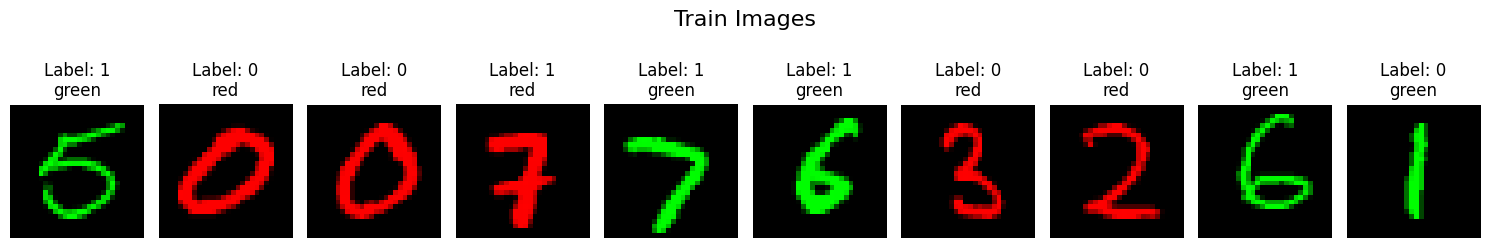

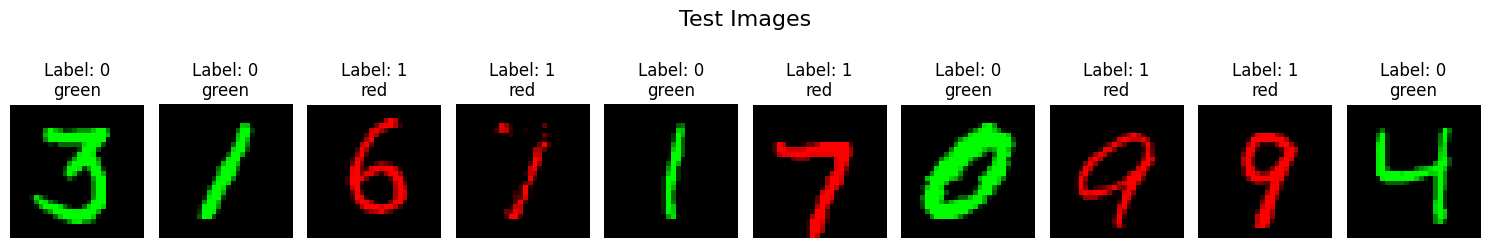

In [ ]:
def show_images(dataset, title, num_images):
    indices = random.sample(range(len(dataset)), num_images)
    plt.figure(figsize=(15, 3))
    for plot_idx, data_idx in enumerate(indices):
        sample = dataset[data_idx]

        if len(sample) == 3:
            image, label, color = sample
        else:
            image, label = sample
            color = "temp"
        temp_image = image.permute(1, 2, 0).numpy()
        plt.subplot(1, num_images, plot_idx + 1)
        plt.imshow(temp_image)
        plt.axis("off")
        plt.title(f"Label: {label.item()}\n{color}")

    plt.suptitle(title, fontsize=16)
    plt.tight_layout()
    plt.show()

show_images(train_dataset, "Train Images", num_images=10)
show_images(test_dataset, "Test Images", num_images=10)

## 2. Train with ERM

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 128
ERM_EPOCHS = 2
JTT_EPOCHS = 3

In [128]:
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

In [129]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),            
            nn.Linear(3 * 28 * 28, 128),
            nn.ReLU(),
            nn.Linear(128, 2)
        )

    def forward(self, x):
        return self.network(x)

In [130]:
erm_model = MLP().to(device)
print(erm_model)

MLP(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2352, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=2, bias=True)
  )
)


In [131]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(erm_model.parameters(), lr=1e-4)

In [ ]:
def train(model, dataloader, criterion, optimizer, device):
    model.train()
    total_loss = 0.0
    total_correct = 0
    total_samples = 0
    for batch in dataloader:
        images = batch[0].to(device)
        labels = batch[1].to(device)
        logits = model(images)
        loss = criterion(logits, labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size

        predictions = torch.argmax(logits, dim=1)
        total_correct += (predictions == labels).sum().item()
        total_samples += batch_size

    average_loss = total_loss / total_samples
    accuracy = total_correct / total_samples
    return average_loss, accuracy

In [ ]:
def evaluate(model, dataloader, criterion, device):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_samples = 0
    with torch.no_grad():
        for batch in dataloader:
            images = batch[0].to(device)
            labels = batch[1].to(device)
            logits = model(images)
            loss = criterion(logits, labels)
            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size
            predictions = torch.argmax(logits, dim=1)
            total_correct += (predictions == labels).sum().item()
            total_samples += batch_size

    average_loss = total_loss / total_samples
    accuracy = total_correct / total_samples
    return average_loss, accuracy

In [134]:
for epoch in range(ERM_EPOCHS):
    train_loss, train_acc = train(erm_model, train_loader, criterion, optimizer, device)
    test_loss, test_acc = evaluate(erm_model, test_loader, criterion, device)
    print(f"Epoch [{epoch + 1}/{ERM_EPOCHS}]")
    print(f"Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc * 100:.2f}%")
    print(f"Test  Loss: {test_loss:.4f} | Test  Accuracy: {test_acc * 100:.2f}%")
    print("-" * 60)

Epoch [1/2]
Train Loss: 0.2067 | Train Accuracy: 94.94%
Test  Loss: 1.9976 | Test  Accuracy: 8.88%
------------------------------------------------------------
Epoch [2/2]
Train Loss: 0.1352 | Train Accuracy: 95.90%
Test  Loss: 1.7418 | Test  Accuracy: 28.65%
------------------------------------------------------------


In [ ]:
train_loss, train_acc = evaluate(model=erm_model, dataloader=train_loader, criterion=criterion, device=device)
test_loss, test_acc = evaluate(model=erm_model, dataloader=test_loader, criterion=criterion, device=device)
print("Final ERM Results\n")
print(f"Train Accuracy : {train_acc * 100:.2f}%")
print(f"Test Accuracy : {test_acc * 100:.2f}%")

Final ERM Results

Train Accuracy : 96.30%
Test Accuracy : 28.65%


## 3. Exatracting the Error Set

In [ ]:
error_set_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=False)
def get_error_indices(model, dataloader, device):
    model.eval()
    error_indices = []
    cur = 0
    with torch.no_grad():
        for batch in dataloader:
            images = batch[0].to(device)
            labels = batch[1].to(device)
            logits = model(images)
            predictions = torch.argmax(logits, dim=1)
            incorrect_mask = predictions != labels
            batch_size = labels.size(0)
            for i in range(batch_size):
                if incorrect_mask[i].item():
                    error_indices.append(cur + i)
            cur += batch_size

    return error_indices

In [ ]:
error_indices = get_error_indices(model=erm_model, dataloader=error_set_loader, device=device)
print("Number of samples in Error Set:", len(error_indices))

Number of samples in Error Set: 2242


## 4. Making Upsampling Dataset

In [ ]:
FACTOR = 50
def upsample(num_original_samples, error_indices, factor):
    original_indices = list(range(num_original_samples))
    extra_error_indices = []
    for idx in error_indices:
        extra_error_indices.extend([idx] * factor)

    upsampled_indices = original_indices + extra_error_indices
    return upsampled_indices

num_original_samples = len(train_dataset)
upsampled_indices = upsample(num_original_samples=num_original_samples, error_indices=error_indices, factor=FACTOR)

print("Original training dataset size:", len(train_dataset))
print("Error set size:", len(error_indices))
print("New upsampled dataset size:", len(upsampled_indices))

Original training dataset size: 60000
Error set size: 2242
New upsampled dataset size: 172100


In [49]:
class UpsampledDataset(Dataset):
    def __init__(self, original_dataset, upsampled_indices):
        self.original_dataset = original_dataset
        self.upsampled_indices = upsampled_indices

    def __len__(self):
        return len(self.upsampled_indices)

    def __getitem__(self, index):
        original_index = self.upsampled_indices[index]
        return self.original_dataset[original_index]

In [50]:
jtt_train_dataset = UpsampledDataset(original_dataset=train_dataset, upsampled_indices=upsampled_indices)
jtt_train_loader = DataLoader(jtt_train_dataset, batch_size=BATCH_SIZE, shuffle=True)
print("JTT upsampled train dataset size:", len(jtt_train_dataset))

JTT upsampled train dataset size: 172100


## 5. Training a New Model

In [51]:
jtt_model = MLP().to(device)
print(jtt_model)

MLP(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2352, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=2, bias=True)
  )
)


In [ ]:
jtt_criterion = nn.CrossEntropyLoss()
jtt_optimizer = torch.optim.Adam(jtt_model.parameters(), lr=1e-4)
for epoch in range(JTT_EPOCHS):
    train_loss, train_acc = train(model=jtt_model, dataloader=jtt_train_loader, criterion=jtt_criterion, optimizer=jtt_optimizer, device=device)
    test_loss, test_acc = evaluate(model=jtt_model, dataloader=test_loader, criterion=jtt_criterion, device=device)
    print(f"Epoch [{epoch + 1}/{JTT_EPOCHS}]")
    print(f"JTT Train Loss: {train_loss:.4f} | JTT Train Accuracy: {train_acc * 100:.2f}%")
    print(f"JTT Test  Loss: {test_loss:.4f} | JTT Test  Accuracy: {test_acc * 100:.2f}%")
    print("-" * 60)

Epoch [1/3]
JTT Train Loss: 0.3407 | JTT Train Accuracy: 86.53%
JTT Test  Loss: 0.2159 | JTT Test  Accuracy: 93.52%
------------------------------------------------------------
Epoch [2/3]
JTT Train Loss: 0.1257 | JTT Train Accuracy: 96.59%
JTT Test  Loss: 0.2220 | JTT Test  Accuracy: 92.47%
------------------------------------------------------------
Epoch [3/3]
JTT Train Loss: 0.0698 | JTT Train Accuracy: 98.47%
JTT Test  Loss: 0.2643 | JTT Test  Accuracy: 90.90%
------------------------------------------------------------


In [56]:
jtt_final_train_loss, jtt_final_train_acc = evaluate(model=jtt_model, dataloader=train_loader, criterion=jtt_criterion, device=device)
jtt_final_test_loss, jtt_final_test_acc = evaluate(model=jtt_model, dataloader=test_loader, criterion=jtt_criterion, device=device)
print("Final JTT Results\n")
print(f"Train Accuracy on original train set: {jtt_final_train_acc * 100:.2f}%")
print(f"Test Accuracy : {jtt_final_test_acc * 100:.2f}%")

Final JTT Results

Train Accuracy on original train set: 97.38%
Test Accuracy : 90.90%


## 6. Training using GCE

In [ ]:
class GCE(nn.Module):
    def __init__(self, q):
        super().__init__()
        self.q = q

    def forward(self, logits, targets):
        probs = torch.softmax(logits, dim=1)
        correct_probs = probs[torch.arange(len(targets), device=targets.device), targets]
        correct_probs = torch.clamp(correct_probs, min=1e-8, max=1.0)
        loss = (1.0 - correct_probs ** self.q) / self.q
        return loss.mean()

In [229]:
gce_model = MLP().to(device)
gce_criterion = GCE(q=0.5)
gce_optimizer = torch.optim.Adam(gce_model.parameters(), lr=1e-4)
print(gce_model)

MLP(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2352, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=2, bias=True)
  )
)


In [230]:
for epoch in range(ERM_EPOCHS):
    train_loss, train_acc = train(model=gce_model, dataloader=train_loader, criterion=gce_criterion, optimizer=gce_optimizer, device=device)
    test_loss, test_acc = evaluate(model=gce_model, dataloader=test_loader, criterion=gce_criterion, device=device)
    print(f"Epoch [{epoch + 1}/{ERM_EPOCHS}]")
    print(f"GCE Train Loss: {train_loss:.4f} | GCE Train Accuracy: {train_acc * 100:.2f}%")
    print(f"GCE Test  Loss: {test_loss:.4f} | GCE Test  Accuracy: {test_acc * 100:.2f}%")
    print("-" * 60)

Epoch [1/2]
GCE Train Loss: 0.1342 | GCE Train Accuracy: 94.91%
GCE Test  Loss: 1.8376 | GCE Test  Accuracy: 0.00%
------------------------------------------------------------
Epoch [2/2]
GCE Train Loss: 0.0915 | GCE Train Accuracy: 95.17%
GCE Test  Loss: 1.5258 | GCE Test  Accuracy: 9.31%
------------------------------------------------------------


In [231]:
gce_final_train_loss, gce_final_train_acc = evaluate(model=gce_model, dataloader=train_loader, criterion=gce_criterion, device=device)
gce_final_test_loss, gce_final_test_acc = evaluate(model=gce_model, dataloader=test_loader, criterion=gce_criterion, device=device)
print("Final GCE Results\n")
print(f"Train Accuracy : {gce_final_train_acc * 100:.2f}%")
print(f"Test Accuracy : {gce_final_test_acc * 100:.2f}%")

Final GCE Results

Train Accuracy : 95.55%
Test Accuracy : 9.31%


In [ ]:
gce_error_set_loader = DataLoader(train_dataset, batch_size=128, shuffle=False)
gce_error_indices = get_error_indices(model=gce_model, dataloader=gce_error_set_loader, device=device)
print("Number of samples in GCE Error Set:", len(gce_error_indices))

Number of samples in GCE Error Set: 2672


In [ ]:
def analyze_error_set(error_indices, labels, colors):
    labels_np = labels.numpy() if torch.is_tensor(labels) else np.array(labels)
    colors_np = np.array(colors)
    error_indices_np = np.array(error_indices)
    error_labels = labels_np[error_indices_np]
    error_colors = colors_np[error_indices_np]
    print("Error Set statistics:")
    print("Total errors:", len(error_indices))
    for class_id in [0, 1]:
        for color in ["red", "green"]:
            count = np.sum((error_labels == class_id) & (error_colors == color))
            percent = 100 * count / len(error_indices)
            print(f"Class {class_id}, Color {color}: {count} samples ({percent:.2f}%)")

In [ ]:
print("ERM Error Set analysis:")
analyze_error_set(error_indices=error_indices, labels=train_binary_labels, colors=train_colors)
print("\nGCE Error Set analysis:")
analyze_error_set(error_indices=gce_error_indices, labels=train_binary_labels, colors=train_colors)

ERM Error Set analysis:
Error Set statistics:
Total errors: 2242
Class 0, Color red: 73 samples (3.26%)
Class 0, Color green: 944 samples (42.11%)
Class 1, Color red: 1123 samples (50.09%)
Class 1, Color green: 102 samples (4.55%)

GCE Error Set analysis:
Error Set statistics:
Total errors: 2672
Class 0, Color red: 0 samples (0.00%)
Class 0, Color green: 1263 samples (47.27%)
Class 1, Color red: 1395 samples (52.21%)
Class 1, Color green: 14 samples (0.52%)
